========== UCB (Manchester United Tactical Selection) ==========
Counter-Attack Strategy selected 257 times
Gegenpressing Style selected 68 times
Wing-Play Dominance selected 675 times
Total Match Points/Goals Generated = 664

========== Thompson Sampling (Manchester United Tactical Selection) ==========
Counter-Attack Strategy selected 279 times
Gegenpressing Style selected 15 times
Wing-Play Dominance selected 706 times
Total Match Points/Goals Generated = 671


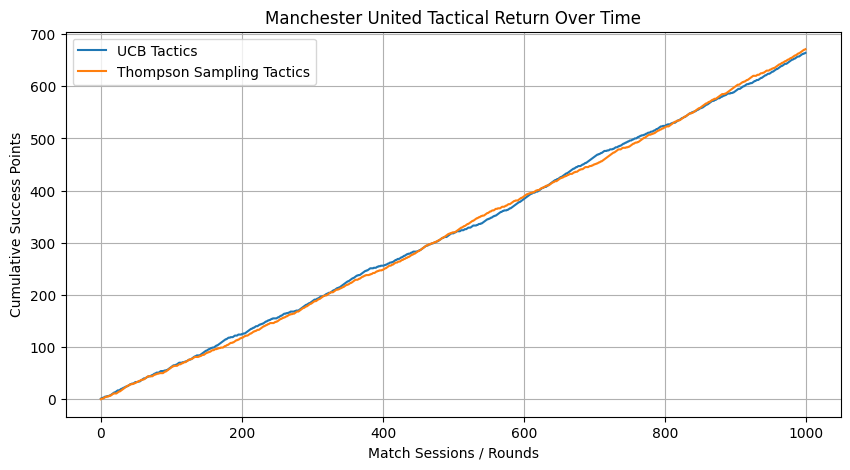

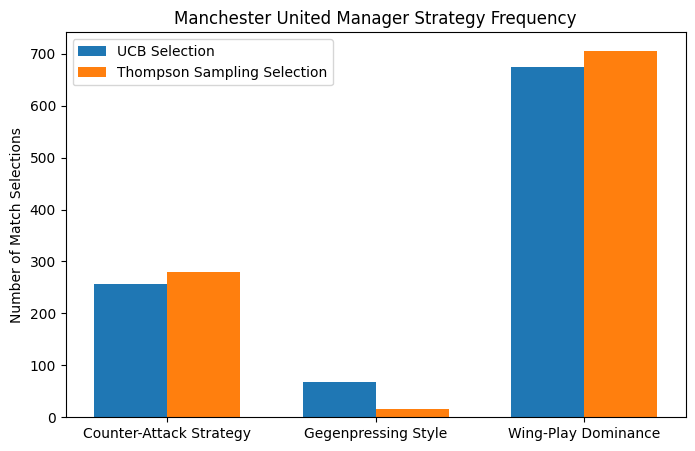

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

arms = ["Counter-Attack Strategy", "Gegenpressing Style", "Wing-Play Dominance"]
probabilities = [0.6, 0.4, 0.7]
n_arms = len(arms)
rounds = 1000

counts_ucb = np.zeros(n_arms)
values_ucb = np.zeros(n_arms)
rewards_ucb = []
cumulative_rewards_ucb = []
total_reward = 0

for t in range(rounds):
    if t < n_arms:
        action = t
    else:
        confidence = np.sqrt((2 * np.log(t + 1)) / counts_ucb)
        ucb = values_ucb + confidence
        action = np.argmax(ucb)

    reward = np.random.binomial(1, probabilities[action])
    counts_ucb[action] += 1
    values_ucb[action] += (reward - values_ucb[action]) / counts_ucb[action]
    total_reward += reward
    rewards_ucb.append(reward)
    cumulative_rewards_ucb.append(total_reward)

print("========== UCB (Manchester United Tactical Selection) ==========")
for i in range(n_arms):
    print(arms[i], "selected", int(counts_ucb[i]), "times")
print("Total Match Points/Goals Generated =", total_reward)

alpha = np.ones(n_arms)
beta = np.ones(n_arms)
counts_ts = np.zeros(n_arms)
rewards_ts = []
cumulative_rewards_ts = []
total_reward = 0

for t in range(rounds):
    samples = np.random.beta(alpha, beta)
    action = np.argmax(samples)
    reward = np.random.binomial(1, probabilities[action])
    counts_ts[action] += 1

    if reward == 1:
        alpha[action] += 1
    else:
        beta[action] += 1

    total_reward += reward
    rewards_ts.append(reward)
    cumulative_rewards_ts.append(total_reward)

print("\n========== Thompson Sampling (Manchester United Tactical Selection) ==========")
for i in range(n_arms):
    print(arms[i], "selected", int(counts_ts[i]), "times")
print("Total Match Points/Goals Generated =", total_reward)

plt.figure(figsize=(10,5))
plt.plot(cumulative_rewards_ucb, label="UCB Tactics")
plt.plot(cumulative_rewards_ts, label="Thompson Sampling Tactics")
plt.xlabel("Match Sessions / Rounds")
plt.ylabel("Cumulative Success Points")
plt.title("Manchester United Tactical Return Over Time")
plt.legend()
plt.grid()
plt.show()

x = np.arange(n_arms)
width = 0.35
plt.figure(figsize=(8,5))
plt.bar(x-width/2, counts_ucb, width, label="UCB Selection")
plt.bar(x+width/2, counts_ts, width, label="Thompson Sampling Selection")
plt.xticks(x, arms)
plt.ylabel("Number of Match Selections")
plt.title("Manchester United Manager Strategy Frequency")
plt.legend()
plt.show()
